# Rainfall in Dhaka and Sylhet, 1981-2025: how consistent are gridded datasets?

**Questions**
1. How much rain does each city get per month and per year?
2. How much of the annual rain falls in the monsoon (June-September)?
3. Are heavy-rain days becoming more frequent?
4. Is annual rainfall trending up or down?
5. Do two independent datasets (NASA POWER and ERA5) agree?

**Data:** NASA POWER daily precipitation (`PRECTOTCORR`, mm/day) and ERA5 via the Open-Meteo archive API. Both are modelled, gridded products, not rain-gauge data.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# ---- Settings you can change ----
DATA_DIR = Path("/content")        # change to Path("/content") on Colab
OUT_DIR = Path("/content/outputs")
OUT_DIR.mkdir(exist_ok=True)

CITIES = {
    "Dhaka": DATA_DIR / "dhaka.csv",
    "Sylhet": DATA_DIR / "sylhet.csv",
}
RAINY_DAY_MM = 1       # a day with >= 1 mm counts as a rainy day
HEAVY_DAY_MM = 50      # a day with >= 50 mm counts as a heavy-rain day
MONSOON_MONTHS = [6, 7, 8, 9]   # June-September

plt.rcParams["figure.dpi"] = 110

## 2. Load the data



In [3]:
def load_power_csv(path):
    """Read a NASA POWER daily CSV into a DataFrame with a date index."""
    path = Path(path)
    lines = path.read_text().splitlines()

    # find where the real table starts
    header_end = next(i for i, line in enumerate(lines) if "-END HEADER-" in line)
    df = pd.read_csv(path, skiprows=header_end + 1)

    # build a proper date from YEAR + day-of-year (DOY)
    df["date"] = pd.to_datetime(df["YEAR"].astype(str), format="%Y") + pd.to_timedelta(df["DOY"] - 1, unit="D")
    df = df.set_index("date").sort_index()
    return df


raw = {city: load_power_csv(path) for city, path in CITIES.items()}

for city, df in raw.items():
    print(city, df.shape)
raw["Dhaka"].head()

Dhaka (16436, 3)
Sylhet (16436, 3)


,YEAR,DOY,PRECTOTCORR
date,,,
1981-01-01,1981,1,0.00
1981-01-02,1981,2,0.00
1981-01-03,1981,3,0.00
1981-01-04,1981,4,0.00
1981-01-05,1981,5,0.03


## 3. Clean and sanity-check

NASA uses **-999** for missing values.

In [4]:
rain = {}
for city, df in raw.items():
    s = df["PRECTOTCORR"].replace(-999, np.nan)
    s.name = "rain_mm"
    rain[city] = s

for city, s in rain.items():
    print(f"--- {city} ---")
    print("Date range:", s.index.min().date(), "to", s.index.max().date())
    print("Missing days:", s.isna().sum(), f"({s.isna().mean():.2%})")
    print("Negative values:", (s < 0).sum())
    print(s.describe().round(2))
    print()

--- Dhaka ---
Date range: 1981-01-01 to 2025-12-31
Missing days: 0 (0.00%)
Negative values: 0
count    16436.00
mean         5.00
std          9.95
min          0.00
25%          0.00
50%          0.70
75%          5.90
max        167.28
Name: rain_mm, dtype: float64

--- Sylhet ---
Date range: 1981-01-01 to 2025-12-31
Missing days: 0 (0.00%)
Negative values: 0
count    16436.00
mean         8.52
std         16.63
min          0.00
25%          0.00
50%          1.13
75%         10.31
max        279.92
Name: rain_mm, dtype: float64



## 4. Summaries





In [7]:
# 4a: monthly totals for each city
monthly = pd.DataFrame({
    "Dhaka": rain["Dhaka"].resample("MS").sum(),
    "Sylhet": rain["Sylhet"].resample("MS").sum(),
})
monthly.head()

# 4b: annual totals for each city
annual = pd.DataFrame({
    "Dhaka": rain["Dhaka"].resample("YS").sum(),
    "Sylhet": rain["Sylhet"].resample("YS").sum(),
})
annual.head()
# 4c: average monthly rainfall (climatology) for each city
climatology = monthly.groupby(monthly.index.month).mean()
climatology.round(1)

# 4d: monsoon rainfall as a percentage of the annual total, per year
monsoon = monthly[monthly.index.month.isin(MONSOON_MONTHS)].resample("YS").sum()
monsoon_pct = (monsoon / annual * 100).round(1)
monsoon_pct.head()

monsoon_pct.mean().round(1)


,0
Dhaka,63.5
Sylhet,64.9


## 5. Rainy days and extremes



In [8]:
# 5a: number of rainy days per year (>= RAINY_DAY_MM)
rainy_days = pd.DataFrame({
    "Dhaka": (rain["Dhaka"] >= RAINY_DAY_MM).resample("YS").sum(),
    "Sylhet": (rain["Sylhet"] >= RAINY_DAY_MM).resample("YS").sum(),
})
rainy_days.head()

# 5b: number of heavy-rain days per year (>= HEAVY_DAY_MM)
heavy_days = pd.DataFrame({
    "Dhaka": (rain["Dhaka"] >= HEAVY_DAY_MM).resample("YS").sum(),
    "Sylhet": (rain["Sylhet"] >= HEAVY_DAY_MM).resample("YS").sum(),
})
heavy_days.head()

# 5c: annual maximum daily rainfall
annual_max = pd.DataFrame({
    "Dhaka": rain["Dhaka"].resample("YS").max(),
    "Sylhet": rain["Sylhet"].resample("YS").max(),
})
annual_max.head()

annual_max.max()


,0
Dhaka,167.28
Sylhet,279.92


## 6. Plots



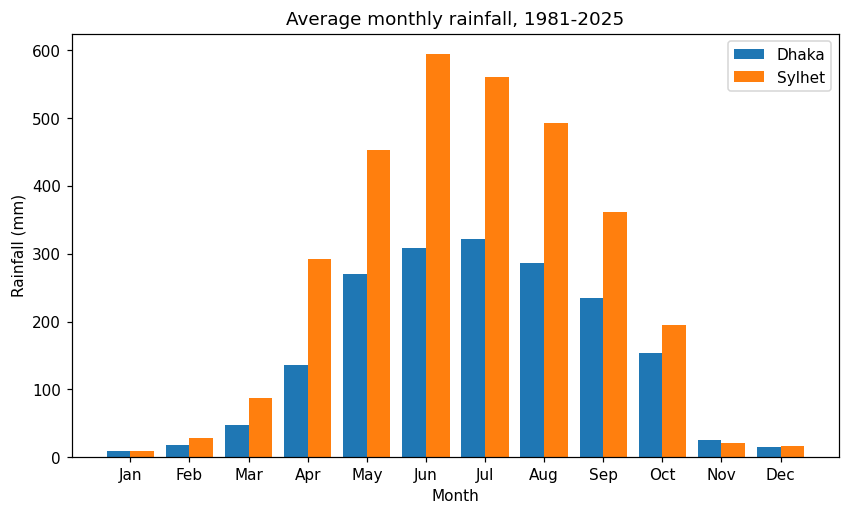

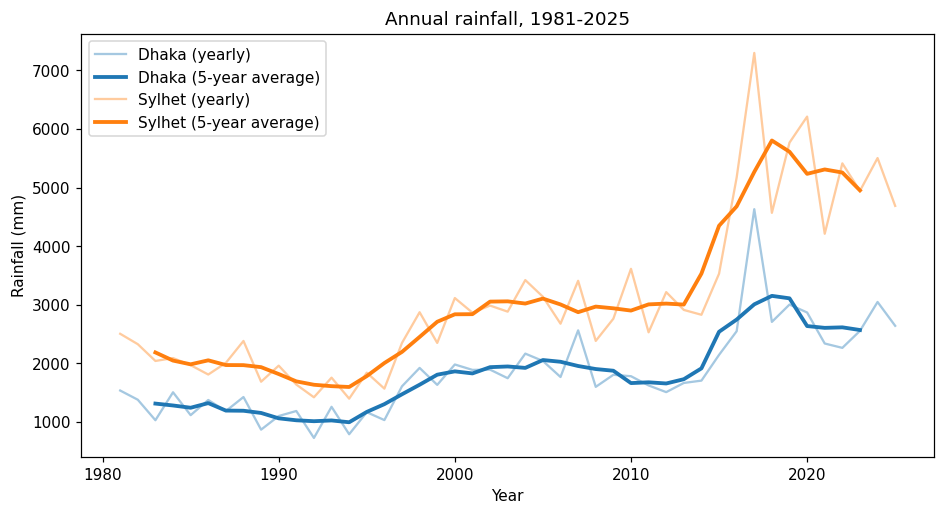

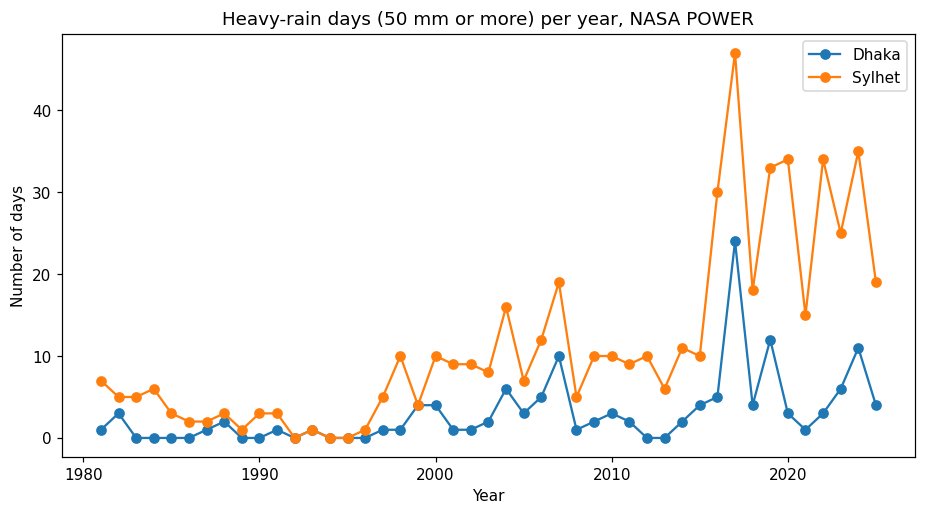

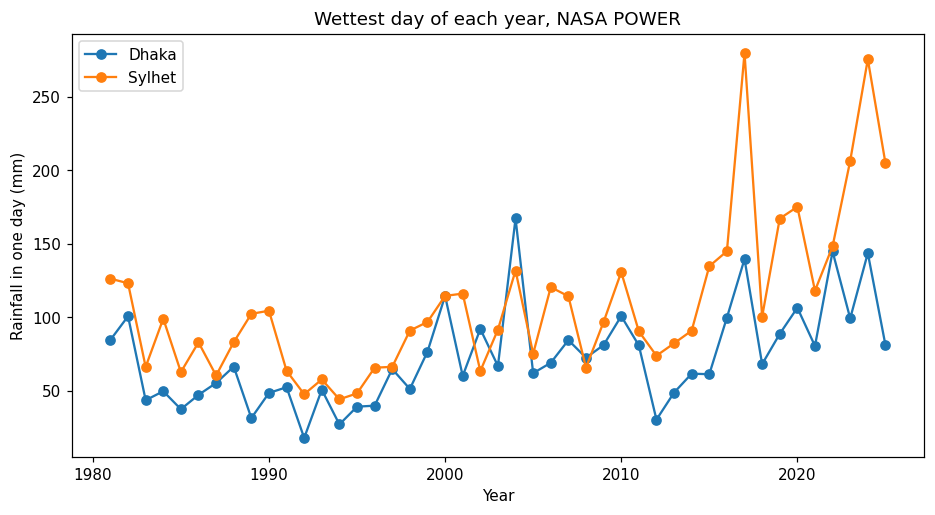

In [9]:
# TODO 6a: monthly climatology bar chart
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
x = np.arange(12)
width = 0.4

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, climatology["Dhaka"], width, label="Dhaka")
plt.bar(x + width/2, climatology["Sylhet"], width, label="Sylhet")
plt.xticks(x, months)
plt.title("Average monthly rainfall, 1981-2025")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.savefig(OUT_DIR / "monthly_climatology.png", bbox_inches="tight")
plt.show()

# TODO 6b: annual rainfall + 5-year rolling mean
years = annual.index.year

plt.figure(figsize=(10, 5))
plt.plot(years, annual["Dhaka"], color="tab:blue", alpha=0.4, label="Dhaka (yearly)")
plt.plot(years, annual["Dhaka"].rolling(5, center=True).mean(), color="tab:blue", linewidth=2.5, label="Dhaka (5-year average)")
plt.plot(years, annual["Sylhet"], color="tab:orange", alpha=0.4, label="Sylhet (yearly)")
plt.plot(years, annual["Sylhet"].rolling(5, center=True).mean(), color="tab:orange", linewidth=2.5, label="Sylhet (5-year average)")
plt.title("Annual rainfall, 1981-2025")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.savefig(OUT_DIR / "annual_rainfall.png", bbox_inches="tight")
plt.show()
# TODO 6c: heavy-rain days per year
# TODO 6c: heavy-rain days per year
plt.figure(figsize=(10, 5))
plt.plot(heavy_days.index.year, heavy_days["Dhaka"], color="tab:blue", marker="o", label="Dhaka")
plt.plot(heavy_days.index.year, heavy_days["Sylhet"], color="tab:orange", marker="o", label="Sylhet")
plt.title("Heavy-rain days (50 mm or more) per year, NASA POWER")
plt.xlabel("Year")
plt.ylabel("Number of days")
plt.legend()
plt.savefig(OUT_DIR / "heavy_rain_days.png", bbox_inches="tight")
plt.show()


# TODO 6d: annual maximum daily rainfall
# TODO 6d: annual maximum daily rainfall
plt.figure(figsize=(10, 5))
plt.plot(annual_max.index.year, annual_max["Dhaka"], color="tab:blue", marker="o", label="Dhaka")
plt.plot(annual_max.index.year, annual_max["Sylhet"], color="tab:orange", marker="o", label="Sylhet")
plt.title("Wettest day of each year, NASA POWER")
plt.xlabel("Year")
plt.ylabel("Rainfall in one day (mm)")
plt.legend()
plt.savefig(OUT_DIR / "annual_max_rainfall.png", bbox_inches="tight")
plt.show()


In [10]:
print(annual.loc["2000":"2012"].mean().round(0))
print(annual.loc["2018":"2025"].mean().round(0))

Dhaka     1872.0
Sylhet    2998.0
dtype: float64
Dhaka     2677.0
Sylhet    5163.0
dtype: float64


In [11]:
print(annual.loc["2008":"2020"].round(0))

             Dhaka  Sylhet
date                      
2008-01-01  1597.0  2382.0
2009-01-01  1803.0  2761.0
2010-01-01  1779.0  3612.0
2011-01-01  1621.0  2528.0
2012-01-01  1507.0  3215.0
2013-01-01  1664.0  2911.0
2014-01-01  1704.0  2828.0
2015-01-01  2143.0  3529.0
2016-01-01  2547.0  5171.0
2017-01-01  4631.0  7298.0
2018-01-01  2706.0  4568.0
2019-01-01  3002.0  5767.0
2020-01-01  2867.0  6211.0


In [12]:
import requests

def get_era5(lat, lon):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": "1981-01-01", "end_date": "2025-12-31",
        "daily": "precipitation_sum", "timezone": "Asia/Dhaka",
    }
    data = requests.get(url, params=params, timeout=120).json()
    return pd.Series(data["daily"]["precipitation_sum"],
                     index=pd.to_datetime(data["daily"]["time"]))

era5 = {"Dhaka": get_era5(23.81, 90.41), "Sylhet": get_era5(24.90, 91.87)}
era5_annual = pd.DataFrame({c: s.resample("YS").sum() for c, s in era5.items()})
era5_annual.loc["2008":"2020"].round(0)

,Dhaka,Sylhet
2008-01-01,1916.0,4408.0
2009-01-01,1812.0,4385.0
2010-01-01,1746.0,6462.0
2011-01-01,1895.0,3854.0
2012-01-01,1624.0,5314.0
2013-01-01,1831.0,4244.0
2014-01-01,1284.0,4149.0
2015-01-01,2259.0,5412.0
2016-01-01,1863.0,5444.0
2017-01-01,2675.0,5776.0


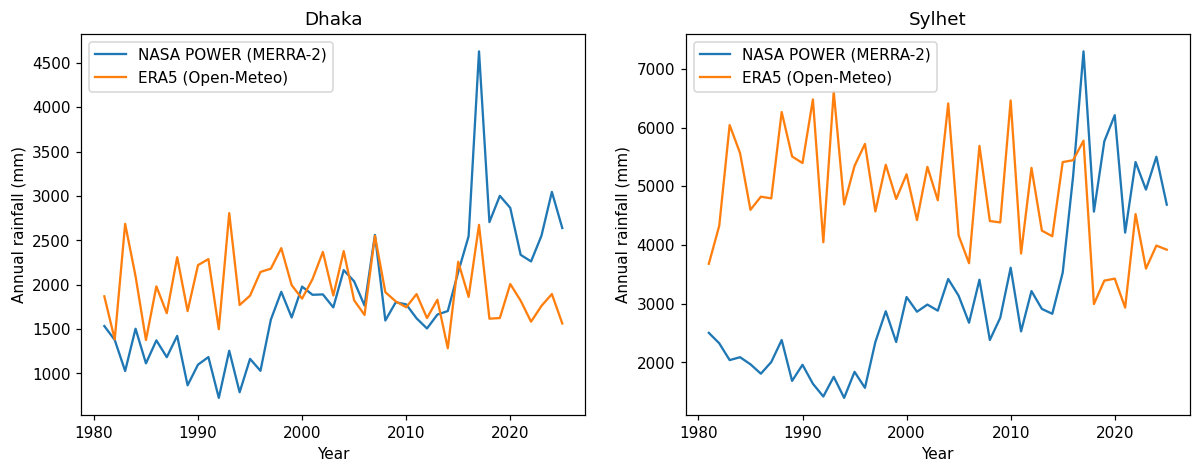

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, city in zip(axes, ["Dhaka", "Sylhet"]):
    ax.plot(annual.index.year, annual[city], label="NASA POWER (MERRA-2)")
    ax.plot(era5_annual.index.year, era5_annual[city], label="ERA5 (Open-Meteo)")
    ax.set_title(city)
    ax.set_xlabel("Year")
    ax.set_ylabel("Annual rainfall (mm)")
    ax.legend()
plt.savefig(OUT_DIR / "dataset_comparison.png", bbox_inches="tight")
plt.show()

In [14]:
for city in ["Dhaka", "Sylhet"]:
    r = annual[city].corr(era5_annual[city])
    print(city, "- correlation of annual totals:", round(r, 2))

ratio = annual / era5_annual
print()
print("NASA divided by ERA5, average per decade (1.0 = they agree):")
print(ratio.groupby(ratio.index.year // 10 * 10).mean().round(2))

Dhaka - correlation of annual totals: 0.13
Sylhet - correlation of annual totals: -0.32

NASA divided by ERA5, average per decade (1.0 = they agree):
      Dhaka  Sylhet
date               
1980   0.69    0.43
1990   0.58    0.37
2000   0.96    0.62
2010   1.26    0.93
2020   1.48    1.40


## 7. Trend test


In [16]:
# TODO 7: linear trend of annual rainfall for each city (slope, p-value)
for city in ["Dhaka", "Sylhet"]:
    for name, data in [("NASA", annual), ("ERA5", era5_annual)]:
        res = stats.linregress(data.index.year, data[city])
        print(f"{city} - {name}: {res.slope * 10:+.0f} mm per decade, p = {res.pvalue:.3f}")

Dhaka - NASA: +417 mm per decade, p = 0.000
Dhaka - ERA5: -50 mm per decade, p = 0.226
Sylhet - NASA: +862 mm per decade, p = 0.000
Sylhet - ERA5: -308 mm per decade, p = 0.004


## 8. Findings

Sylhet gets about 3,110 mm of rain a year in the NASA POWER data, roughly 70% more than Dhaka's 1,830 mm. In both cities about 64% of the yearly rain falls in the monsoon months (June to September). Heavy-rain days and the wettest days of the year rise after about 2015 in the NASA data, but ERA5 does not show the same rise. The two datasets barely agree year to year (correlation 0.13 for Dhaka, -0.32 for Sylhet), and the trend even flips direction for Sylhet (+862 mm per decade in NASA, -308 in ERA5), so I can't say whether rainfall is really changing. Limitations: both datasets are modelled rather than gauge data, there are only two locations, and I had no ground observations to check which dataset is closer to the truth.
